# Environment Setup and Data Download

In [2]:
!pip install -q kaggle

!kaggle datasets download -d shashwatwork/dataco-smart-supply-chain-for-big-data-analysis

!unzip -q dataco-smart-supply-chain-for-big-data-analysis.zip -d /content/data/

print("Dataset downloaded and extracted.")

Dataset URL: https://www.kaggle.com/datasets/shashwatwork/dataco-smart-supply-chain-for-big-data-analysis
License(s): CC0-1.0
dataco-smart-supply-chain-for-big-data-analysis.zip: Skipping, found more recently modified local copy (use --force to force download)
replace /content/data/DataCoSupplyChainDataset.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: N
Dataset downloaded and extracted.


# Imports and Data Loading

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             recall_score, precision_score, f1_score,
                             roc_auc_score, roc_curve)
import warnings
warnings.filterwarnings('ignore')

# Set visualization style
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 120

# Load the dataset (latin-1 encoding because of special characters)
df = pd.read_csv("/content/data/DataCoSupplyChainDataset.csv", encoding="latin-1")
print(f"Raw dataset shape: {df.shape}")

Raw dataset shape: (180519, 53)


# Data Cleaning

In [4]:
# Drop leakage columns (post-delivery information)
leakage_cols = ['Delivery Status', 'Days for shipping (real)']
df = df.drop(columns=[c for c in leakage_cols if c in df.columns])

# Drop high-null columns
high_null_cols = ['Product Description', 'Order Zipcode']
df = df.drop(columns=[c for c in high_null_cols if c in df.columns])

# Drop PII columns
pii_cols = ['Customer Email', 'Customer Password', 'Customer Fname',
            'Customer Lname', 'Customer Street']
df = df.drop(columns=[c for c in pii_cols if c in df.columns])

# Drop columns with a single unique value (no predictive power)
for col in df.columns:
    if df[col].nunique() <= 1:
        df = df.drop(columns=[col])

# Parse order date
df['order_date'] = pd.to_datetime(df['order date (DateOrders)'], format='%m/%d/%Y %H:%M', errors='coerce')

# Drop rows with missing target
df = df.dropna(subset=['Late_delivery_risk'])

print(f"Cleaned dataset shape: {df.shape}")
print(f"Target distribution:\n{df['Late_delivery_risk'].value_counts(normalize=True).round(3)}")

Cleaned dataset shape: (180519, 44)
Target distribution:
Late_delivery_risk
1    0.548
0    0.452
Name: proportion, dtype: float64


# Feature Engineering

In [5]:
# 1. Shipping Pressure Index
df['Shipping_Pressure_Index'] = df['Days for shipment (scheduled)'] / (df['Order Item Quantity'] + 1)

# 2. Express Flag
df['Is_Express'] = df['Shipping Mode'].isin(['First Class', 'Same Day']).astype(int)

# 3. High Discount Flag
discount_threshold = df['Order Item Discount Rate'].quantile(0.75)
df['High_Discount_Flag'] = (df['Order Item Discount Rate'] > discount_threshold).astype(int)

# 4. Order Complexity Score
df['Order_Complexity_Score'] = df['Order Item Quantity'] * df['Order Item Product Price']

# 5. Temporal features
df['Order_DOW'] = df['order_date'].dt.dayofweek
df['Order_Month'] = df['order_date'].dt.month

# 6. Regional Congestion Score (computed later on training data only to avoid leakage)
# Placeholder: will be filled after train-test split

print("Feature engineering complete. New columns added.")

Feature engineering complete. New columns added.


# Train-Test Split and Preprocessing

In [7]:
# Define feature columns: drop identifiers, dates, and target
drop_for_X = ['Late_delivery_risk', 'order_date', 'order id', 'Customer Id',
              'Order Id', 'Product Card Id', 'Product Category Id',
              'Department Id', 'Order Customer Id', 'Category Id',
              'Product Image', 'Customer City', 'Order City',
              'Customer Country', 'Order Country', 'Customer State',
              'Order State', 'Market', 'Order Region']
drop_for_X = [c for c in drop_for_X if c in df.columns]

X = df.drop(columns=drop_for_X)
y = df['Late_delivery_risk']

# Separate categorical and numerical columns
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()

print(f"Categorical columns: {len(cat_cols)}")
print(f"Numerical columns: {len(num_cols)}")

# Train-test split (stratified, 80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Training set: {X_train.shape[0]} rows")
print(f"Test set: {X_test.shape[0]} rows")

# --- Preprocessing: Label Encoding for categorical columns (fit on train only) ---
label_encoders = {}
unseen_counts = {}

for col in cat_cols:
    le = LabelEncoder()
    # Fit on training data
    X_train[col] = le.fit_transform(X_train[col].astype(str))

    # Build a fast lookup dictionary
    mapping = {cls: idx for idx, cls in enumerate(le.classes_)}

    # Fast vectorized map for test set (unseen -> -1)
    X_test_col = X_test[col].astype(str)
    X_test[col] = X_test_col.map(mapping).fillna(-1).astype(int)

    # Track unseen categories
    unseen = (~X_test_col.isin(le.classes_)).sum()
    unseen_counts[col] = unseen

    label_encoders[col] = le

print("Label encoding complete.")
print("Unseen category counts in test set:")
for col, cnt in unseen_counts.items():
    print(f"  {col}: {cnt}")

# --- Preprocessing: Scaling for numerical columns (fit on train only) ---
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

# --- Regional Congestion Score (now that split is done) ---
# Compute historical late rate per region on training data only
if 'Order Region' in df.columns:
    region_late_rate = df.loc[X_train.index].groupby('Order Region')['Late_delivery_risk'].mean()
    X_train['Regional_Congestion_Score'] = X_train.index.map(
        lambda idx: region_late_rate.get(df.loc[idx, 'Order Region'], df['Late_delivery_risk'].mean())
    )
    X_test['Regional_Congestion_Score'] = X_test.index.map(
        lambda idx: region_late_rate.get(df.loc[idx, 'Order Region'], df['Late_delivery_risk'].mean())
    )
    # Scale the new feature
    X_train[['Regional_Congestion_Score']] = scaler.fit_transform(X_train[['Regional_Congestion_Score']])
    X_test[['Regional_Congestion_Score']] = scaler.transform(X_test[['Regional_Congestion_Score']])

print("Preprocessing complete. Data ready for training.")

Categorical columns: 9
Numerical columns: 23
Training set: 144415 rows
Test set: 36104 rows
Label encoding complete.
Unseen category counts in test set:
  Type: 0
  Category Name: 0
  Customer Segment: 0
  Department Name: 0
  order date (DateOrders): 5353
  Order Status: 0
  Product Name: 0
  shipping date (DateOrders): 5041
  Shipping Mode: 0
Preprocessing complete. Data ready for training.


# Model Training and Evaluation

In [13]:
# Drop the handful of training rows with NaN in Customer Zipcode
nan_mask = X_train['Customer Zipcode'].isnull()
print(f"Dropping {nan_mask.sum()} training rows with NaN Customer Zipcode")
X_train = X_train.loc[~nan_mask]
y_train = y_train.loc[~nan_mask]
# Class imbalance ratio for XGBoost
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Logistic Regression": LogisticRegression(
        class_weight='balanced', max_iter=1000, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        class_weight='balanced', n_estimators=100, random_state=42, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        scale_pos_weight=scale_pos_weight, n_estimators=100,
        random_state=42, eval_metric='logloss', use_label_encoder=False
    )
}

results = {}

for name, model in models.items():
    print(f"\n{'='*50}")
    print(f"Training: {name}")
    print('='*50)

    # Train
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else None

    # Metrics
    recall = recall_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_proba) if y_proba is not None else None

    results[name] = {
        'Recall': recall,
        'Precision': precision,
        'F1': f1,
        'ROC-AUC': roc_auc,
        'Model': model
    }

    print(f"Recall:    {recall:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"F1 Score:  {f1:.4f}")
    if roc_auc:
        print(f"ROC-AUC:   {roc_auc:.4f}")

    print(f"\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=['On-Time', 'Late']))

Dropping 3 training rows with NaN Customer Zipcode

Training: Logistic Regression
Recall:    0.5815
Precision: 0.8012
F1 Score:  0.6739
ROC-AUC:   0.7172

Classification Report:
              precision    recall  f1-score   support

     On-Time       0.62      0.82      0.71     16308
        Late       0.80      0.58      0.67     19796

    accuracy                           0.69     36104
   macro avg       0.71      0.70      0.69     36104
weighted avg       0.72      0.69      0.69     36104


Training: Random Forest
Recall:    0.6887
Precision: 0.8687
F1 Score:  0.7683
ROC-AUC:   0.8698

Classification Report:
              precision    recall  f1-score   support

     On-Time       0.70      0.87      0.78     16308
        Late       0.87      0.69      0.77     19796

    accuracy                           0.77     36104
   macro avg       0.78      0.78      0.77     36104
weighted avg       0.79      0.77      0.77     36104


Training: XGBoost
Recall:    0.8181
Precision:

# Model Comparison and Selection

In [14]:
comparison_df = pd.DataFrame({
    name: {k: v for k, v in metrics.items() if k != 'Model'}
    for name, metrics in results.items()
}).T.round(4)

print("\n" + "="*60)
print("MODEL COMPARISON SUMMARY")
print("="*60)
print(comparison_df.sort_values('Recall', ascending=False))

# Select best model by F1 (balance of recall and precision)
best_model_name = max(results, key=lambda x: results[x]['F1'])
best_model = results[best_model_name]['Model']
print(f"\nBest model by F1: {best_model_name}")


MODEL COMPARISON SUMMARY
                     Recall  Precision      F1  ROC-AUC
XGBoost              0.8181     0.9167  0.8646   0.9409
Random Forest        0.6887     0.8687  0.7683   0.8698
Logistic Regression  0.5815     0.8012  0.6739   0.7172

Best model by F1: XGBoost


# Feature Importance

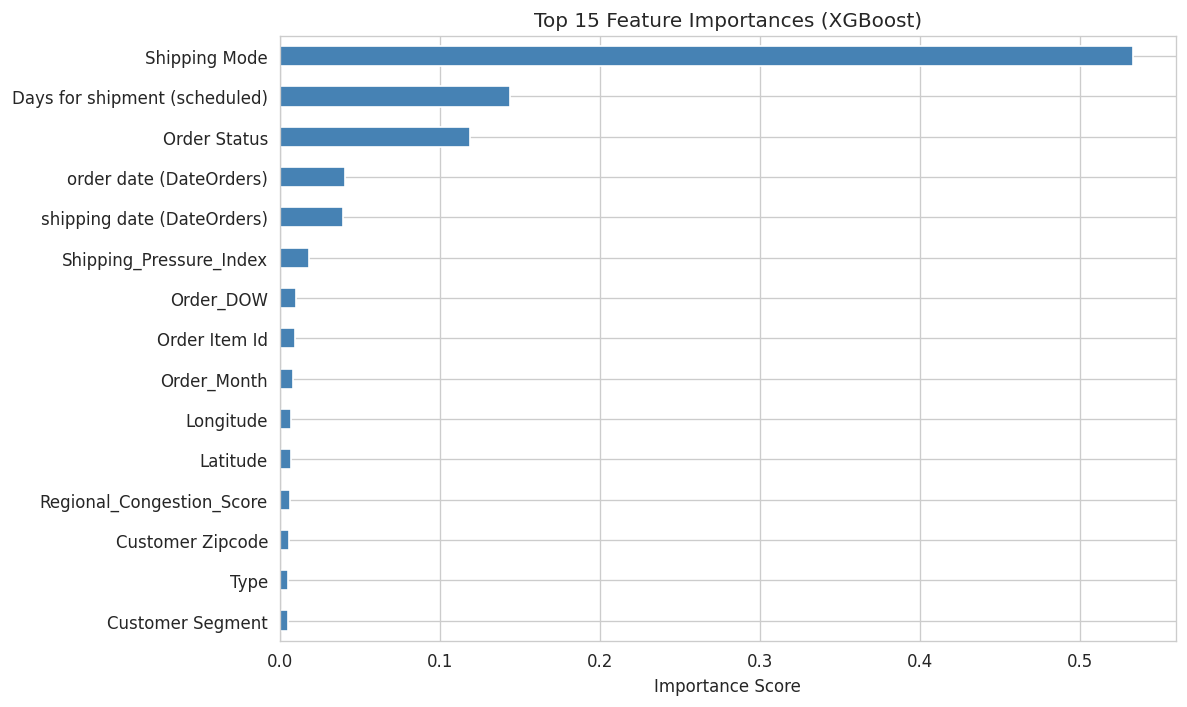


Top 10 Features:
Shipping Mode                    0.533007
Days for shipment (scheduled)    0.143927
Order Status                     0.119092
order date (DateOrders)          0.040804
shipping date (DateOrders)       0.039788
Shipping_Pressure_Index          0.018446
Order_DOW                        0.010178
Order Item Id                    0.009562
Order_Month                      0.008315
Longitude                        0.007048
dtype: float32


In [15]:
if hasattr(best_model, 'feature_importances_'):
    importances = pd.Series(
        best_model.feature_importances_,
        index=X_train.columns
    ).sort_values(ascending=False).head(15)

    plt.figure(figsize=(10, 6))
    importances.plot(kind='barh', color='steelblue')
    plt.xlabel('Importance Score')
    plt.title(f'Top 15 Feature Importances ({best_model_name})')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

    print("\nTop 10 Features:")
    print(importances.head(10))

# Confusion Matrix Visualization

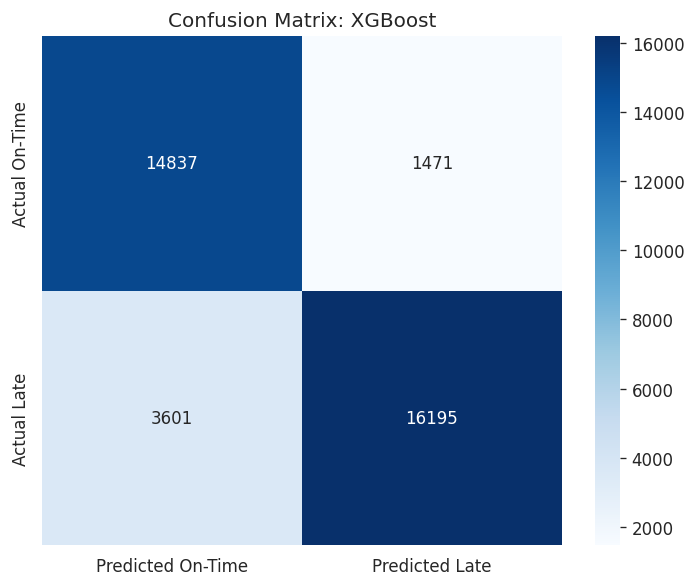

In [16]:
y_pred_best = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted On-Time', 'Predicted Late'],
            yticklabels=['Actual On-Time', 'Actual Late'])
plt.title(f'Confusion Matrix: {best_model_name}')
plt.tight_layout()
plt.show()

# ROC Curve Comparison

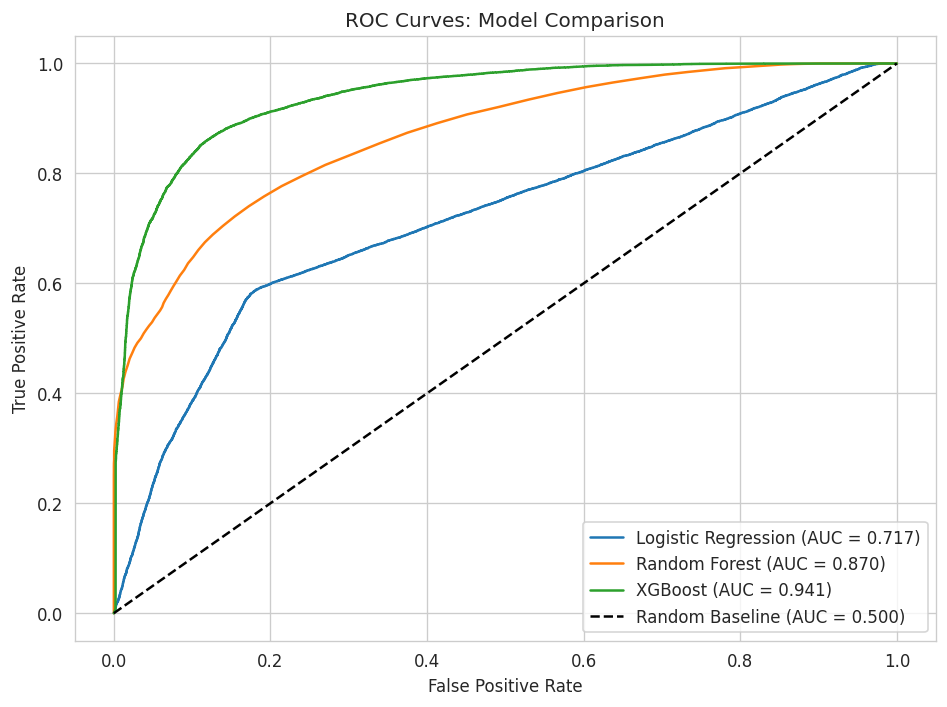

In [17]:
plt.figure(figsize=(8, 6))
for name, metrics in results.items():
    model = metrics['Model']
    if hasattr(model, 'predict_proba'):
        y_proba = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        auc = metrics['ROC-AUC']
        plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Baseline (AUC = 0.500)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves: Model Comparison')
plt.legend()
plt.tight_layout()
plt.show()

# Optimization Analysis (Cost-Benefit Simulation)

In [18]:
print("\n" + "="*60)
print("OPTIMIZATION ANALYSIS: COST-BENEFIT OF PREDICTIVE INTERVENTION")
print("="*60)

# Simulate operational costs (hypothetical but illustrative values)
COST_INTERVENTION = 15.0  # INR: cost to expedite/prioritize one flagged shipment
COST_LATE_DELIVERY = 50.0  # INR: cost of a late delivery (customer credit, reputation)

# Using the best model's predictions
tn, fp, fn, tp = cm.ravel()

# Without model: no interventions, all late shipments incur late cost
baseline_late_cost = (tp + fn) * COST_LATE_DELIVERY
print(f"\nBaseline (no model): {tp + fn} late shipments × ₹{COST_LATE_DELIVERY} = ₹{baseline_late_cost:,.2f}")

# With model: intervene on all predicted late (TP + FP)
# Successful interventions: assume 40% of true positives are saved
SAVE_RATE = 0.40
saved_late = int(tp * SAVE_RATE)
remaining_late_cost = (fn + (tp - saved_late)) * COST_LATE_DELIVERY
intervention_cost = (tp + fp) * COST_INTERVENTION
total_with_model = remaining_late_cost + intervention_cost

print(f"\nWith model intervention:")
print(f"  Flagged shipments (TP + FP): {tp + fp}")
print(f"  Intervention cost: {tp + fp} × ₹{COST_INTERVENTION} = ₹{intervention_cost:,.2f}")
print(f"  Late shipments saved (40% of TP): {saved_late}")
print(f"  Remaining late cost: {fn + (tp - saved_late)} × ₹{COST_LATE_DELIVERY} = ₹{remaining_late_cost:,.2f}")
print(f"  Total cost with model: ₹{total_with_model:,.2f}")

net_savings = baseline_late_cost - total_with_model
print(f"\nNet savings: ₹{net_savings:,.2f}")
print(f"ROI: {(net_savings / intervention_cost * 100) if intervention_cost > 0 else 0:.1f}%")


OPTIMIZATION ANALYSIS: COST-BENEFIT OF PREDICTIVE INTERVENTION

Baseline (no model): 19796 late shipments × ₹50.0 = ₹989,800.00

With model intervention:
  Flagged shipments (TP + FP): 17666
  Intervention cost: 17666 × ₹15.0 = ₹264,990.00
  Late shipments saved (40% of TP): 6478
  Remaining late cost: 13318 × ₹50.0 = ₹665,900.00
  Total cost with model: ₹930,890.00

Net savings: ₹58,910.00
ROI: 22.2%


# Save Model for Deployment

In [19]:
import joblib

# Save the best model, scaler, and encoders
joblib.dump(best_model, '/content/best_late_delivery_model.pkl')
joblib.dump(scaler, '/content/scaler.pkl')
joblib.dump(label_encoders, '/content/label_encoders.pkl')

print("\nModel artifacts saved:")
print("  - best_late_delivery_model.pkl")
print("  - scaler.pkl")
print("  - label_encoders.pkl")

# Download to local machine
from google.colab import files
files.download('/content/best_late_delivery_model.pkl')

print("\n" + "="*60)
print("WEEK 4 PREDICTIVE MODELING PIPELINE COMPLETE")
print("="*60)


Model artifacts saved:
  - best_late_delivery_model.pkl
  - scaler.pkl
  - label_encoders.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


WEEK 4 PREDICTIVE MODELING PIPELINE COMPLETE
